<a href="https://colab.research.google.com/github/virenmarcellya12/Analisis-Deret-Waktu/blob/main/Tugas_Kelompok_Minggu_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok 4 -- PENDUGAAN PARAMETER

## Anggota :  
##1. Haniyathul Husna (M0501251011)
##2. Siti zakiah (M0501251044)
##3. Viren Marcellya Clarenda Siboro (M0501251047)


# SOAL 1
Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:

Kelompok 4: ARIMA (1,0,0) dan ARIMA (2,2,1)

seed : 2502


## Pembangkitan Data Simulasi ARIMA (1,0,0) dan ARIMA (2,2,1)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Agar simulasi dapat direproduksi
np.random.seed(2502)

# Panjang deret waktu
n = 300
burn_in = 300

# Ragam galat = 1
sigma = 1

# Parameter ARIMA(1,0,0)
phi_ar1 = 0.6

# Parameter ARIMA(2,2,1)
phi1 = 0.5
phi2 = -0.3
theta1 = 0.4


Keterangan Parameter Simulasi

Simulasi menggunakan panjang deret waktu sebanyak 300 pengamatan dengan burn-in 300 untuk mengurangi pengaruh nilai awal. Jadi, total data yang dibangkitkan adalah 600 pengamatan, tetapi yang dianalisis hanya 300 pengamatan terakhir.

Galat dibangkitkan dari distribusi normal dengan rata-rata 0 dan ragam 1 ($\sigma^2=1$). Nilai *random seed* ditetapkan sebesar 2502.

Parameter yang digunakan adalah:

- ARIMA(1,0,0): $\phi_1=0,6$, memenuhi syarat stasioneritas karena $|\phi_1|< 1$.
- ARIMA(2,2,1): $\phi_1=0,5$, $\phi_2=-0,3$, dan $\theta_1=0,4$.

Kedua model selanjutnya digunakan untuk membangkitkan deret waktu dan membandingkan hasil pendugaan parameter menggunakan metode Kuadrat Terkecil (LS) dan Maximum Likelihood Estimation (MLE).

### ARIMA (1,0,0)

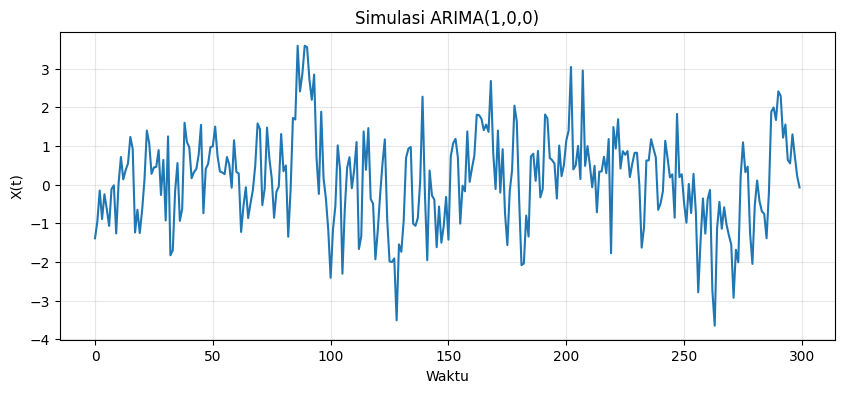

In [ ]:
# Galat white noise
e1 = np.random.normal(0, sigma, n + burn_in)

# Membentuk deret AR(1)
x1 = np.zeros(n + burn_in)

for t in range(1, n + burn_in):
    x1[t] = phi_ar1 * x1[t-1] + e1[t]

# Mengambil 300 pengamatan terakhir
x1 = x1[burn_in:]

# Plot
plt.figure(figsize=(10, 4))
plt.plot(x1)
plt.title("Simulasi ARIMA(1,0,0)")
plt.xlabel("Waktu")
plt.ylabel("X(t)")
plt.grid(alpha=0.3)
plt.show()


Berdasarkan grafik, deret waktu ARIMA(1,0,0) berfluktuasi secara acak di sekitar rata-rata nol tanpa menunjukkan tren yang jelas. Penyebaran data juga terlihat relatif konstan sepanjang waktu. Hal ini mengindikasikan bahwa deret waktu bersifat stasioner dalam rata-rata dan ragam, sesuai dengan parameter $\phi_1=0,6$ yang memenuhi syarat stasioneritas $|\phi_1|<1$.

### ARIMA (2,2,1)

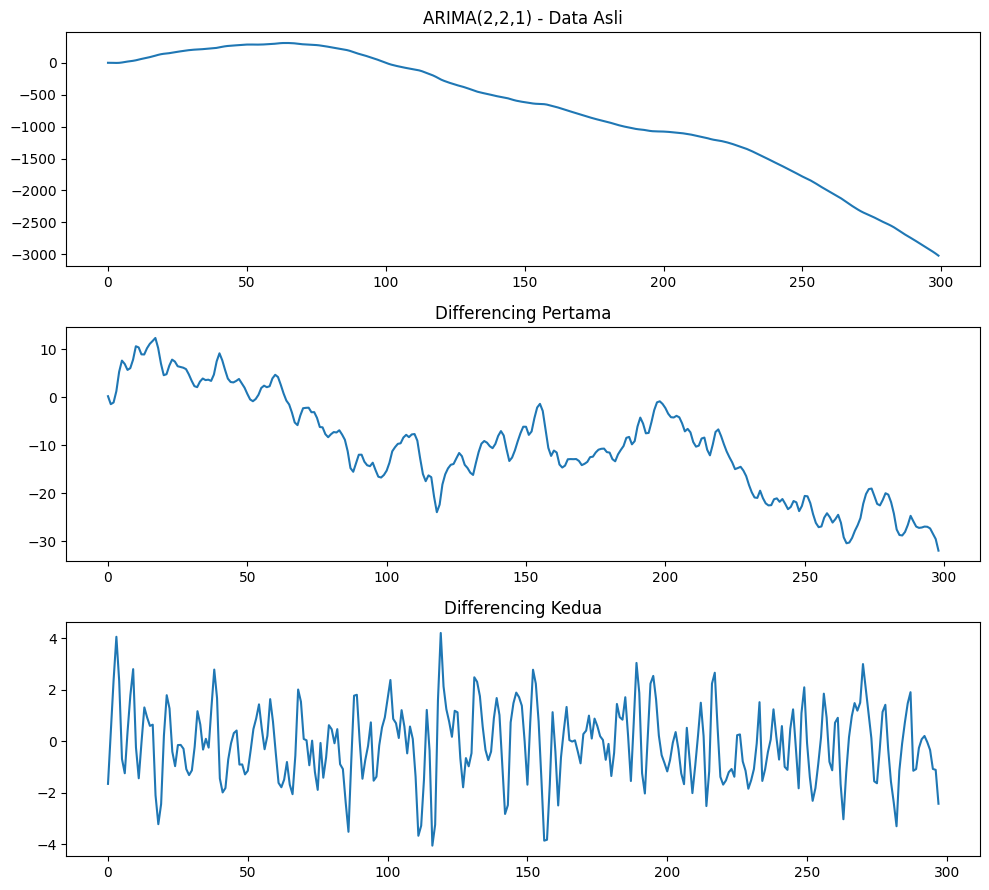

In [ ]:
# Galat white noise
e2 = np.random.normal(0, sigma, n + burn_in)

# Simulasi proses ARMA(2,1) yang stasioner
w = np.zeros(n + burn_in)

for t in range(2, n + burn_in):
    w[t] = (
        phi1 * w[t-1]
        + phi2 * w[t-2]
        + e2[t]
        + theta1 * e2[t-1]
    )

w = w[burn_in:]

# Integrasi dua kali -> ARIMA(2,2,1)
x2 = np.cumsum(np.cumsum(w))

# Differencing kembali
diff1 = np.diff(x2, n=1)
diff2 = np.diff(x2, n=2)

# Visualisasi
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

ax[0].plot(x2)
ax[0].set_title("ARIMA(2,2,1) - Data Asli")

ax[1].plot(diff1)
ax[1].set_title("Differencing Pertama")

ax[2].plot(diff2)
ax[2].set_title("Differencing Kedua")

plt.tight_layout()
plt.show()


Berdasarkan grafik, data ARIMA(2,2,1) menunjukkan pola tren menurun sehingga bersifat tidak stasioner. Setelah differencing pertama, data masih menunjukkan perubahan rata-rata dan pola yang belum stabil. Namun, setelah differencing kedua, data berfluktuasi secara acak di sekitar rata-rata nol dengan penyebaran yang relatif konstan.

Hal ini mengindikasikan bahwa deret waktu menjadi stasioner setelah differencing kedua (d=2), sesuai dengan karakteristik model ARIMA(2,2,1)

### Cek Stasioneritas ARIMA (1,0,0) dan ARIMA (2,2,1)

In [ ]:

def uji_adf(data, nama):
    hasil = adfuller(data, regression="c",
                     autolag="AIC")

    print(f"\n{nama}")
    print(f"ADF Statistic : {hasil[0]:.4f}")
    print(f"P-value       : {hasil[1]:.4f}")

    if hasil[1] < 0.05:
        print("Tolak H0: data deret waktu stasioner")
    else:
        print("Gagal menolak H0: belum cukup bukti")
        print("bahwa data deret waktu dikatakan stasioner, artinya data masih belum stasioner")

uji_adf(x1, "ARIMA(1,0,0)")
uji_adf(x2, "ARIMA(2,2,1) - Data Asli")
uji_adf(diff1, "Differencing Pertama")
uji_adf(diff2, "Differencing Kedua")



ARIMA(1,0,0)
ADF Statistic : -4.7781
P-value       : 0.0001
Tolak H0: data deret waktu stasioner

ARIMA(2,2,1) - Data Asli
ADF Statistic : 1.6937
P-value       : 0.9981
Gagal menolak H0: belum cukup bukti
bahwa data deret waktu dikatakan stasioner, artinya data masih belum stasioner

Differencing Pertama
ADF Statistic : -0.8178
P-value       : 0.8139
Gagal menolak H0: belum cukup bukti
bahwa data deret waktu dikatakan stasioner, artinya data masih belum stasioner

Differencing Kedua
ADF Statistic : -9.5016
P-value       : 0.0000
Tolak H0: data deret waktu stasioner


/tmp/ipykernel_3760/597422648.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data, regression="c",
/tmp/ipykernel_3760/597422648.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data, regression="c",
/tmp/ipykernel_3760/597422648.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and au

## Pendugaan parameter ARIMA(1,0,0)
Model yang kita gunakan adalah:
$$[X_t=0.6X_{t-1}+\varepsilon_t
]$$

Parameter sebenarnya adalah $$(\phi_1=0.6)$$


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd

# Nilai parameter sebenarnya
phi_true = 0.6

# ===== Least Squares (LS) =====
# OLS tanpa konstanta
y = x1[1:]
x_lag = x1[:-1]

phi_ls = np.sum(x_lag * y) / np.sum(x_lag**2)

# ===== Maximum Likelihood (MLE) =====
model_mle_100 = ARIMA(
    x1,
    order=(1, 0, 0),
    trend="n"
)

hasil_mle_100 = model_mle_100.fit()
phi_mle = hasil_mle_100.arparams[0]

# ===== Tabel perbandingan =====
tabel_100 = pd.DataFrame({
    "Parameter": ["phi1", "phi1"],
    "Metode": ["LS", "MLE"],
    "Nilai Sebenarnya": [phi_true, phi_true],
    "Hasil Estimasi": [phi_ls, phi_mle]
})

tabel_100["Error"] = (
    tabel_100["Hasil Estimasi"]
    - tabel_100["Nilai Sebenarnya"]
)

tabel_100["Error Absolut"] = abs(tabel_100["Error"])

print("Perbandingan Estimasi ARIMA(1,0,0)")
display(tabel_100.round(4))


Perbandingan Estimasi ARIMA(1,0,0)


,Parameter,Metode,Nilai Sebenarnya,Hasil Estimasi,Error,Error Absolut
0,phi1,LS,0.6,0.5707,-0.0293,0.0293
1,phi1,MLE,0.6,0.5713,-0.0287,0.0287


### Tabel Hasil Pendugaan Parameter ARIMA(1,0,0)

| Parameter | Nilai Sebenarnya | Metode LS | Metode MLE |
|:---|---:|---:|---:|
| $\phi_1$ | 0,6 | 0,5707 | 0,5713 |
| Error $(\hat{\phi}_1-\phi_1)$ | 0 | -0,0293 | -0,0287 |
| Error Absolut | 0 | 0,0293 | 0,0287 |


### Interpretasi Hasil

Model ARIMA(1,0,0) memiliki parameter sebenarnya sebesar $\phi_1=0,6$.

Berdasarkan hasil simulasi, diperoleh:

- Metode LS: $\hat{\phi}_{1,LS}=0,5707$
- Metode MLE: $\hat{\phi}_{1,MLE}=0,5713$

Kedua metode menghasilkan estimasi yang mendekati nilai parameter sebenarnya. Metode LS menghasilkan error sebesar -0,0293, sedangkan MLE sebesar -0,0287.

Nilai error negatif menunjukkan bahwa kedua metode cenderung menghasilkan estimasi lebih rendah daripada parameter sebenarnya pada simulasi ini.

Berdasarkan error absolut, metode MLE (0,0287) sedikit lebih kecil dibandingkan LS (0,0293). Dengan demikian, MLE menghasilkan estimasi yang sedikit lebih dekat dengan parameter sebenarnya pada simulasi ini.



## Pendugaan Parameter ARIMA(2,2,1)

Model yang digunakan adalah:

$$
(1-\phi_1 B-\phi_2 B^2)(1-B)^2X_t
=(1+\theta_1 B)\varepsilon_t
$$

Dengan melakukan differencing sebanyak dua kali:

$$
W_t=(1-B)^2X_t
$$

Sehingga model ARIMA(2,2,1) dapat dituliskan sebagai:

$$
W_t=0.5W_{t-1}-0.3W_{t-2}
+\varepsilon_t+0.4\varepsilon_{t-1}
$$

Parameter sebenarnya adalah:

$$
\phi_1=0.5,\quad
\phi_2=-0.3,\quad
\theta_1=0.4
$$


In [ ]:

from scipy.optimize import minimize

# Parameter sebenarnya
parameter_true = np.array([0.5, -0.3, 0.4])

# Differencing kedua
w = np.diff(x2, n=2)

# ===== Conditional Least Squares (CSS) =====
def fungsi_css(params, data):
    phi1, phi2, theta1 = params

    # Menghitung residual secara rekursif
    e = np.zeros(len(data))

    for t in range(2, len(data)):
        e[t] = (
            data[t]
            - phi1 * data[t-1]
            - phi2 * data[t-2]
            - theta1 * e[t-1]
        )

    return np.sum(e[2:]**2)

# Kendala stasioneritas AR(2)
def kendala_stasioner(params):
    p1, p2, _ = params
    return np.array([
        0.999 - p1 - p2,
        0.999 + p1 - p2,
        0.999 + p2
    ])

# Optimisasi CSS
hasil_css = minimize(
    fungsi_css,
    x0=[0.2, -0.1, 0.2],
    args=(w,),
    method="SLSQP",
    bounds=[
        (-0.999, 0.999),
        (-0.999, 0.999),
        (-0.999, 0.999)
    ],
    constraints=[{
        "type": "ineq",
        "fun": kendala_stasioner
    }],
    options={"maxiter": 2000, "ftol": 1e-10}
)

if not hasil_css.success:
    raise RuntimeError(hasil_css.message)

estimasi_css = hasil_css.x

# ===== Maximum Likelihood (MLE) =====
model_mle_221 = ARIMA(
    x2,
    order=(2, 2, 1),
    trend="n",
    enforce_stationarity=True,
    enforce_invertibility=True
)

hasil_mle_221 = model_mle_221.fit()

estimasi_mle = np.r_[
    hasil_mle_221.arparams,
    hasil_mle_221.maparams
]

# ===== Tabel Perbandingan =====
tabel_221 = pd.DataFrame({
    "Parameter": ["phi1", "phi2", "theta1"] * 2,
    "Metode": ["LS"] * 3 + ["MLE"] * 3,
    "Nilai Sebenarnya": np.tile(parameter_true, 2),
    "Hasil Estimasi": np.r_[estimasi_css, estimasi_mle]
})

tabel_221["Error"] = (
    tabel_221["Hasil Estimasi"]
    - tabel_221["Nilai Sebenarnya"]
)

tabel_221["Error Absolut"] = abs(tabel_221["Error"])

print("Perbandingan Estimasi ARIMA(2,2,1)")
display(tabel_221.round(4))


Perbandingan Estimasi ARIMA(2,2,1)


,Parameter,Metode,Nilai Sebenarnya,Hasil Estimasi,Error,Error Absolut
0,phi1,LS,0.5,0.6653,0.1653,0.1653
1,phi2,LS,-0.3,-0.4335,-0.1335,0.1335
2,theta1,LS,0.4,0.3011,-0.0989,0.0989
3,phi1,MLE,0.5,0.6637,0.1637,0.1637
4,phi2,MLE,-0.3,-0.4329,-0.1329,0.1329
5,theta1,MLE,0.4,0.3011,-0.0989,0.0989


## Tabel Hasil Pendugaan Parameter ARIMA(2,2,1)

Model ARIMA(2,2,1) menggunakan parameter sebenarnya
$\phi_1=0,5$, $\phi_2=-0,3$, dan $\theta_1=0,4$.

### Perbandingan Metode Least Squares dan Maximum Likelihood

| Parameter | Nilai Sebenarnya | Metode LS/CSS | Metode MLE |
|:---:|---:|---:|---:|
| $\phi_1$ | 0,5 | 0,6653 | 0,6637 |
| $\phi_2$ | -0,3 | -0,4335 | -0,4329 |
| $\theta_1$ | 0,4 | 0,3011 | 0,3011 |
| Error $\phi_1$ | 0 | 0,1653 | 0,1637 |
| Error $\phi_2$ | 0 | -0,1335 | -0,1329 |
| Error $\theta_1$ | 0 | -0,0989 | -0,0989 |
| Error Absolut $\phi_1$ | 0 | 0,1653 | 0,1637 |
| Error Absolut $\phi_2$ | 0 | 0,1335 | 0,1329 |
| Error Absolut $\theta_1$ | 0 | 0,0989 | 0,0989 |

### Interpretasi Hasil

Berdasarkan hasil simulasi ARIMA(2,2,1) dengan 300 pengamatan, pendugaan parameter dilakukan menggunakan metode Least Squares(LS) dan Maximum Likelihood Estimation (MLE).

1. Parameter Autoregressive Pertama ($\phi_1$)

Parameter sebenarnya adalah $\phi_1=0,5$. Metode LS menghasilkan estimasi sebesar 0,6653, sedangkan MLE sebesar 0,6637.

Kedua metode menghasilkan estimasi lebih tinggi daripada nilai sebenarnya . Error absolut MLE sebesar 0,1637 sedikit lebih kecil dibandingkan LS sebesar 0,1653. Hal ini menunjukkan bahwa MLE memberikan estimasi yang sedikit lebih dekat dengan nilai sebenarnya.

2. Parameter Autoregressive Kedua ($\phi_2$)

Parameter sebenarnya adalah $\phi_2=-0,3$. Metode LS menghasilkan estimasi sebesar -0,4335, sedangkan MLE sebesar -0,4329.

Kedua metode menghasilkan estimasi yang lebih negatif daripada nilai sebenarnya . Error absolut MLE sebesar 0,1329 sedikit lebih kecil dibandingkan LS sebesar 0,1335. Dengan demikian, MLE memberikan hasil estimasi yang sedikit lebih dekat dengan parameter sebenarnya.

3. Parameter Moving Average Pertama ($\theta_1$)

Parameter sebenarnya adalah $\theta_1=0,4$. Metode LS dan MLE sama-sama menghasilkan estimasi sebesar 0,3011 setelah pembulatan empat angka desimal.

Kedua metode menghasilkan estimasi lebih rendah daripada parameter sebenarnya , dengan error absolut sebesar 0,0989. Berdasarkan hasil pembulatan, kedua metode memiliki tingkat kedekatan estimasi yang sama untuk parameter ini.

### Kesimpulan

Berdasarkan satu simulasi model ARIMA(2,2,1), metode LS dan MLE menghasilkan estimasi parameter yang relatif berdekatan. Metode MLE memberikan error absolut sedikit lebih kecil pada parameter $\phi_1$ dan $\phi_2$, sedangkan pada parameter $\theta_1$ kedua metode menghasilkan error absolut yang sama setelah pembulatan. Dengan demikian, MLE sedikit lebih unggul berdasarkan error absolut pada simulasi ini.


# SOAL 2
Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh

## SIMULASI 30 ULANGAN ARIMA(1,0,0)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display

In [ ]:
# MENENTUKAN PARAMETER SIMULASI
n = 300
burn_in = 300
sigma = 1

# Parameter sebenarnya ARIMA(1,0,0)
phi_true = 0.6

# Jumlah pengulangan
B = 30

# Menyimpan hasil estimasi setiap ulangan
hasil = []

In [ ]:
for b in range(1, B + 1):

    # Bangkitkan galat white noise
    e = np.random.normal(
        loc=0,
        scale=sigma,
        size=n + burn_in
    )

    # Bangkitkan deret AR(1)
    x = np.zeros(n + burn_in)

    for t in range(1, n + burn_in):
        x[t] = phi_true * x[t-1] + e[t]

    # Ambil 300 observasi setelah burn-in
    x = x[burn_in:]

    # ========================================================
    # A. ESTIMASI KUADRAT TERKECIL (LS)
    # ========================================================

    y = x[1:]
    x_lag = x[:-1]

    phi_ls = np.sum(x_lag * y) / np.sum(x_lag**2)

    # ========================================================
    # B. ESTIMASI KEMUNGKINAN MAKSIMUM (MLE)
    # ========================================================

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        model_mle = ARIMA(
            x,
            order=(1, 0, 0),
            trend="n"
        )

        hasil_mle = model_mle.fit()

    phi_mle = hasil_mle.arparams[0]

    # Simpan hasil setiap ulangan
    hasil.append({
        "Ulangan": b,
        "Phi_Sebenarnya": phi_true,
        "Phi_LS": phi_ls,
        "Phi_MLE": phi_mle,
        "Error_LS": phi_ls - phi_true,
        "Error_MLE": phi_mle - phi_true
    })

# Ubah hasil menjadi DataFrame
hasil_df = pd.DataFrame(hasil)

# ------------------------------------------------------------
# MENAMPILKAN HASIL ESTIMASI 30 ULANGAN
# ------------------------------------------------------------

print("HASIL ESTIMASI PARAMETER 30 ULANGAN")
display(hasil_df.round(5))

# ------------------------------------------------------------
# MENGHITUNG BIAS DAN RAGAM PENDUGA
# ------------------------------------------------------------

bias_ls = hasil_df["Phi_LS"].mean() - phi_true
bias_mle = hasil_df["Phi_MLE"].mean() - phi_true

ragam_ls = hasil_df["Phi_LS"].var(ddof=1)
ragam_mle = hasil_df["Phi_MLE"].var(ddof=1)

mse_ls = np.mean(hasil_df["Error_LS"]**2)
mse_mle = np.mean(hasil_df["Error_MLE"]**2)

ringkasan = pd.DataFrame({
    "Metode": ["LS", "MLE"],
    "Parameter Sebenarnya": [phi_true, phi_true],
    "Rata-rata Estimasi": [
        hasil_df["Phi_LS"].mean(),
        hasil_df["Phi_MLE"].mean()
    ],
    "Bias": [bias_ls, bias_mle],
    "Ragam Penduga": [ragam_ls, ragam_mle],
    "MSE": [mse_ls, mse_mle]
})

print("\nRINGKASAN BIAS DAN RAGAM PENDUGA")
display(ringkasan.round(5))


HASIL ESTIMASI PARAMETER 30 ULANGAN


,Ulangan,Phi_Sebenarnya,Phi_LS,Phi_MLE,Error_LS,Error_MLE
0,1,0.6,0.56468,0.56285,-0.03532,-0.03715
1,2,0.6,0.54207,0.54175,-0.05793,-0.05825
2,3,0.6,0.53020,0.53299,-0.06980,-0.06701
3,4,0.6,0.57797,0.57630,-0.02203,-0.02370
4,5,0.6,0.54939,0.55035,-0.05061,-0.04965
5,6,0.6,0.54635,0.54538,-0.05365,-0.05462
6,7,0.6,0.60237,0.60472,0.00237,0.00472
7,8,0.6,0.55910,0.55796,-0.04090,-0.04204
8,9,0.6,0.55891,0.55797,-0.04109,-0.04203
9,10,0.6,0.59517,0.59318,-0.00483,-0.00682



RINGKASAN BIAS DAN RAGAM PENDUGA


,Metode,Parameter Sebenarnya,Rata-rata Estimasi,Bias,Ragam Penduga,MSE
0,LS,0.6,0.58128,-0.01872,0.00254,0.00280
1,MLE,0.6,0.58099,-0.01901,0.00248,0.00275


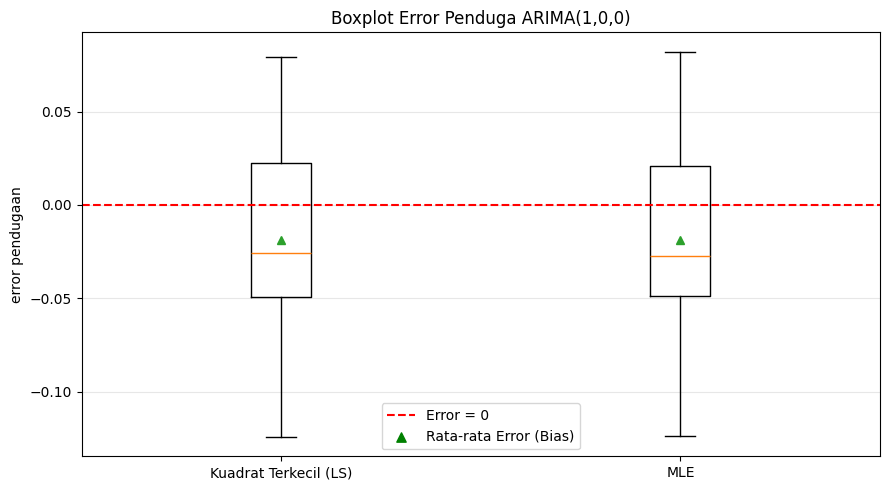

In [ ]:
# ------------------------------------------------------------
# BOXPLOT ERROR PENDUGA
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        hasil_df["Error_LS"],
        hasil_df["Error_MLE"]
    ],
    tick_labels=["Kuadrat Terkecil (LS)", "MLE"],
    showmeans=True
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error = 0"
)

plt.scatter(
        [], [],
        marker="^",
        color="green",
        s=45,
        label="Rata-rata Error (Bias)"
    )

plt.title("Boxplot Error Penduga ARIMA(1,0,0)")
plt.ylabel("error pendugaan")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Perbandingan Bias, Ragam, dan MSE Penduga ARIMA(1,0,0)

Simulasi ARIMA(1,0,0) dilakukan sebanyak 30 ulangan
dengan panjang deret waktu 300 pengamatan.
Parameter sebenarnya yang digunakan adalah
$\phi_1=0,6$.

Pendugaan parameter dilakukan menggunakan metode
Least Squares (LS) dan Maximum Likelihood
Estimation (MLE).

Berikut Ringkasan Hasil Pendugaan Parameter

| Metode | Parameter Sebenarnya | Rata-rata Estimasi | Bias | Ragam | MSE |
|:---:|---:|---:|---:|---:|---:|
| LS | 0,6 | 0,58128 | -0,01872 | 0,00254 | 0,00280 |
| MLE | 0,6 | 0,58099 | -0,01901 | 0,00248 | 0,00275 |


Perbandingan Berdasarkan Bias :

Bias merupakan selisih antara rata-rata hasil
estimasi dari 30 ulangan dengan parameter sebenarnya.

$$
\operatorname{Bias}(\hat{\phi}_1)
=\frac{1}{30}\sum_{i=1}^{30}
(\hat{\phi}_{1,i}-\phi_1)
$$

Semakin kecil nilai absolut bias, semakin dekat
rata-rata estimasi terhadap parameter sebenarnya.

| Metode | Bias | Bias Absolut |
|:---:|---:|---:|
| LS | -0,01872 | 0,01872 |
| MLE | -0,01901 | 0,01901 |


Interpretasi:

Metode LS menghasilkan bias sebesar -0,01872,
sedangkan MLE menghasilkan bias sebesar -0,01901.

Kedua metode memiliki bias negatif, yang menunjukkan
bahwa rata-rata estimasi parameter $\phi_1$ lebih
rendah daripada nilai sebenarnya, yaitu 0,6.

Berdasarkan nilai absolut bias, metode LS memiliki
bias lebih kecil dibandingkan MLE.

Dengan demikian, metode LS lebih baik berdasarkan
kriteria bias pada simulasi ini, meskipun
perbedaannya relatif kecil.



Perbandingan Berdasarkan Ragam :

Ragam digunakan untuk mengukur variasi hasil
estimasi parameter dari 30 ulangan simulasi.

$$
s^2_{\hat{\phi}_1}
=\frac{1}{29}\sum_{i=1}^{30}
(\hat{\phi}_{1,i}-\overline{\hat{\phi}}_1)^2
$$

Semakin kecil ragam, semakin stabil atau konsisten
hasil estimasi antarulangan.

| Metode | Ragam Penduga | Keterangan |
|:---:|---:|:---:|
| LS | 0,00254 | Lebih besar |
| MLE | 0,00248 | Paling stabil |

Interpretasi:

Metode LS menghasilkan ragam sebesar 0,00254,
sedangkan MLE menghasilkan ragam sebesar 0,00248.

Nilai ragam MLE yang lebih kecil menunjukkan bahwa
hasil estimasi parameter $\phi_1$ menggunakan MLE
memiliki variasi antarulangan yang lebih rendah.

Dengan demikian, MLE lebih stabil dibandingkan
LS berdasarkan kriteria ragam, meskipun
perbedaannya sangat kecil.


Perbandingan Berdasarkan Mean Squared Error (MSE) :

MSE digunakan untuk mengevaluasi kesalahan
pendugaan berdasarkan gabungan bias dan ragam.

$$
\operatorname{MSE}(\hat{\phi}_1)
=\frac{1}{30}\sum_{i=1}^{30}
(\hat{\phi}_{1,i}-\phi_1)^2
$$

Semakin kecil nilai MSE, semakin baik kinerja
pendugaan berdasarkan kesalahan kuadrat rata-rata.

| Metode | MSE | Keterangan |
|:---:|---:|:---:|
| LS | 0,00280 | Lebih besar |
| MLE | 0,00275 | MSE terkecil |

Interpretasi:

Metode LS menghasilkan MSE sebesar 0,00280,
sedangkan MLE sebesar 0,00275.

Metode MLE memiliki MSE yang sedikit lebih kecil
dibandingkan LS. Hal ini menunjukkan bahwa
MLE memiliki kinerja pendugaan yang sedikit
lebih baik berdasarkan kriteria MSE.



Kesimpulan :

Berdasarkan hasil simulasi ARIMA(1,0,0)
sebanyak 30 ulangan, diperoleh kesimpulan:

1. Berdasarkan bias, metode LS menghasilkan
   bias absolut lebih kecil, yaitu 0,01872,
   dibandingkan MLE sebesar 0,01901.

2. Berdasarkan ragam, metode MLE lebih stabil
   karena memiliki ragam sebesar 0,00248,
   lebih kecil dibandingkan LS sebesar 0,00254.

3. Berdasarkan MSE, metode MLE menghasilkan
   kesalahan kuadrat rata-rata lebih kecil,
   yaitu 0,00275 dibandingkan LS sebesar 0,00280.

Secara keseluruhan, metode MLE lebih
unggul berdasarkan ragam dan MSE, sedangkan
LS lebih baik berdasarkan bias.



## SIMULASI 30 ULANGAN ARIMA(2,2,1)

In [ ]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from statsmodels.tsa.arima.model import ARIMA
import warnings

# ================================
# 1. Pengaturan Simulasi
# ================================

n = 300
n_ulangan = 30
burn_in = 300
sigma = 1

phi1_true = 0.5
phi2_true = -0.3
theta1_true = 0.4

# Tanpa mengatur random seed
rng = np.random.default_rng()

# ================================
# 2. Fungsi Simulasi ARIMA(2,2,1)
# ================================

def simulasi_arima221():
    N = n + burn_in

    e = rng.normal(0, sigma, N)
    w = np.zeros(N)

    for t in range(2, N):
        w[t] = (
            phi1_true * w[t-1]
            + phi2_true * w[t-2]
            + e[t]
            + theta1_true * e[t-1]
        )

    # Buang burn-in, lalu integrasi dua kali
    w = w[burn_in:]
    x = np.cumsum(np.cumsum(w))

    return x

# ================================
# 3. Fungsi LS/CSS
# ================================

def fungsi_css(params, w):
    phi1, phi2, theta1 = params
    residual = np.zeros(len(w))

    for t in range(2, len(w)):
        residual[t] = (
            w[t]
            - phi1 * w[t-1]
            - phi2 * w[t-2]
            - theta1 * residual[t-1]
        )

    return np.sum(residual[2:]**2)

def kendala_stasioner(params):
    p1, p2, _ = params

    return np.array([
        0.999 - p1 - p2,
        0.999 + p1 - p2,
        0.999 + p2
    ])

def estimasi_css(x):
    w = np.diff(x, n=2)

    # Titik awal tetap, bukan parameter sebenarnya
    hasil = minimize(
        fungsi_css,
        x0=[0.2, -0.1, 0.2],
        args=(w,),
        method="SLSQP",
        bounds=[(-0.999, 0.999)] * 3,
        constraints=[{
            "type": "ineq",
            "fun": kendala_stasioner
        }],
        options={"maxiter": 2000, "ftol": 1e-10}
    )

    if not hasil.success:
        raise RuntimeError(hasil.message)

    return hasil.x

# ================================
# 4. Fungsi MLE
# ================================

def estimasi_mle(x):
    model = ARIMA(
        x,
        order=(2, 2, 1),
        trend="n",
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        hasil = model.fit()

    if not hasil.mle_retvals.get("converged", False):
        raise RuntimeError("Optimisasi MLE tidak konvergen")

    return np.r_[hasil.arparams, hasil.maparams]

# ================================
# 5. Simulasi 30 Ulangan
# ================================

data_hasil = []

for i in range(1, n_ulangan + 1):

    # Bangkitkan data baru setiap ulangan
    x = simulasi_arima221()

    # Pendugaan LS/CSS dan MLE
    css = estimasi_css(x)
    mle = estimasi_mle(x)

    data_hasil.append({
        "Ulangan": i,

        "phi1_LS": css[0],
        "phi2_LS": css[1],
        "theta1_LS": css[2],

        "phi1_MLE": mle[0],
        "phi2_MLE": mle[1],
        "theta1_MLE": mle[2]
    })

    print(f"Ulangan {i}/{n_ulangan} selesai")

# Hasil dalam DataFrame
hasil_30 = pd.DataFrame(data_hasil)

print("\nHasil Estimasi 30 Ulangan ARIMA(2,2,1)")
display(hasil_30.round(4))


Ulangan 1/30 selesai
Ulangan 2/30 selesai
Ulangan 3/30 selesai
Ulangan 4/30 selesai
Ulangan 5/30 selesai
Ulangan 6/30 selesai
Ulangan 7/30 selesai
Ulangan 8/30 selesai
Ulangan 9/30 selesai
Ulangan 10/30 selesai
Ulangan 11/30 selesai
Ulangan 12/30 selesai
Ulangan 13/30 selesai
Ulangan 14/30 selesai
Ulangan 15/30 selesai
Ulangan 16/30 selesai
Ulangan 17/30 selesai
Ulangan 18/30 selesai
Ulangan 19/30 selesai
Ulangan 20/30 selesai
Ulangan 21/30 selesai
Ulangan 22/30 selesai
Ulangan 23/30 selesai
Ulangan 24/30 selesai
Ulangan 25/30 selesai
Ulangan 26/30 selesai
Ulangan 27/30 selesai
Ulangan 28/30 selesai
Ulangan 29/30 selesai
Ulangan 30/30 selesai

Hasil Estimasi 30 Ulangan ARIMA(2,2,1)


,Ulangan,phi1_LS,phi2_LS,theta1_LS,phi1_MLE,phi2_MLE,theta1_MLE
0,1,0.5608,-0.3402,0.3692,0.5644,-0.3439,0.3617
1,2,0.5780,-0.3961,0.3734,0.5775,-0.3969,0.3735
2,3,0.4392,-0.3397,0.4014,0.4323,-0.3343,0.4070
3,4,0.3909,-0.1824,0.5254,0.3882,-0.1802,0.5252
4,5,0.6657,-0.4396,0.2919,0.6646,-0.4389,0.2898
5,6,0.4841,-0.2423,0.4388,0.4816,-0.2384,0.4421
6,7,0.4971,-0.3282,0.4012,0.4844,-0.3210,0.4130
7,8,0.6560,-0.4224,0.1777,0.6471,-0.4187,0.1868
8,9,0.3658,-0.1770,0.5636,0.3745,-0.1861,0.5531
9,10,0.4929,-0.2834,0.4226,0.4901,-0.2821,0.4224


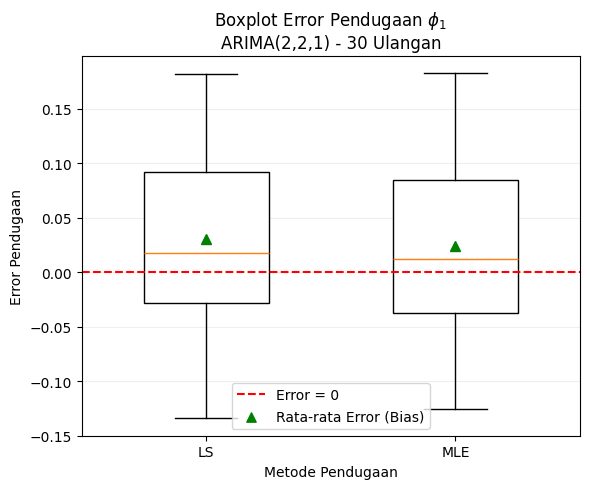

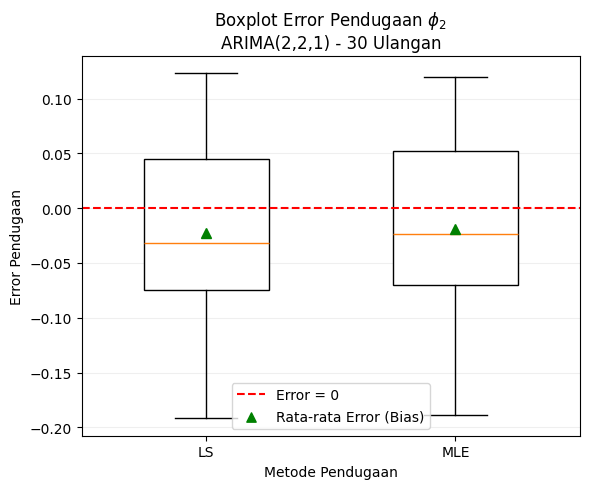

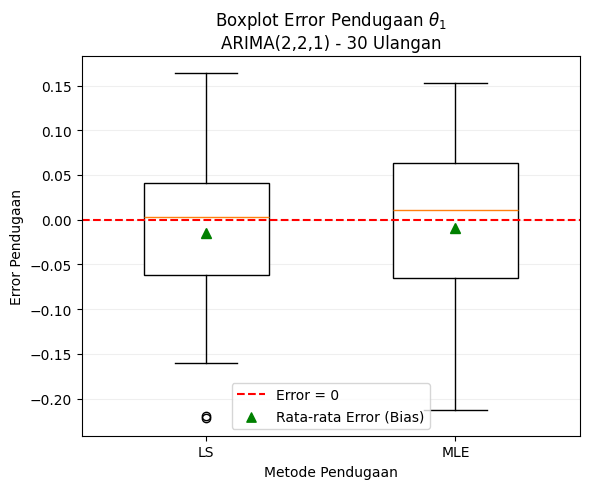

In [ ]:

import matplotlib.pyplot as plt

# Parameter sebenarnya
parameter_asli = {
    "phi1": 0.5,
    "phi2": -0.3,
    "theta1": 0.4
}

# Simbol matematika
simbol = {
    "phi1": r"$\phi_1$",
    "phi2": r"$\phi_2$",
    "theta1": r"$\theta_1$"
}

# Membuat boxplot terpisah untuk setiap parameter
for param, nilai_asli in parameter_asli.items():

    error_ls = hasil_30[f"{param}_LS"] - nilai_asli
    error_mle = hasil_30[f"{param}_MLE"] - nilai_asli

    plt.figure(figsize=(6, 5))

    bp = plt.boxplot(
        [error_ls, error_mle],
        tick_labels=["LS", "MLE"],
        patch_artist=True,
        widths=0.5,
        showmeans=True,
        meanprops=dict(
            marker="^",
            markerfacecolor="green",
            markeredgecolor="green",
            markersize=7
        )
    )

    # Warna kotak putih
    for patch in bp["boxes"]:
        patch.set_facecolor("white")

    # Garis error nol
    plt.axhline(
        0,
        color="red",
        linestyle="--",
        label="Error = 0"
    )

    # Segitiga rata-rata untuk legenda
    plt.scatter(
        [], [],
        marker="^",
        color="green",
        s=45,
        label="Rata-rata Error (Bias)"
    )

    plt.title(
        f"Boxplot Error Pendugaan {simbol[param]}\n"
        "ARIMA(2,2,1) - 30 Ulangan"
    )

    plt.xlabel("Metode Pendugaan")
    plt.ylabel("Error Pendugaan")
    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()


In [ ]:

import numpy as np
import pandas as pd

# Parameter sebenarnya
parameter_asli = {
    "phi1": 0.5,
    "phi2": -0.3,
    "theta1": 0.4
}

# Menghitung kembali bias, ragam, dan MSE
ringkasan = []

for param, nilai_asli in parameter_asli.items():
    for metode in ["LS", "MLE"]:

        estimasi = hasil_30[f"{param}_{metode}"]

        ringkasan.append({
            "Parameter": param,
            "Metode": metode,
            "Bias": estimasi.mean() - nilai_asli,
            "Ragam": estimasi.var(ddof=1),
            "MSE": np.mean((estimasi - nilai_asli)**2)
        })

tabel_ringkasan = pd.DataFrame(ringkasan)

print("Tabel Bias, Ragam, dan MSE")
display(tabel_ringkasan.round(6))



Tabel Bias, Ragam, dan MSE


,Parameter,Metode,Bias,Ragam,MSE
0,phi1,LS,0.030585,0.008953,0.009590
1,phi1,MLE,0.024557,0.008792,0.009102
2,phi2,LS,-0.022387,0.006897,0.007168
3,phi2,MLE,-0.018675,0.006965,0.007081
4,theta1,LS,-0.014792,0.008943,0.008864
5,theta1,MLE,-0.008841,0.008835,0.008619



## Perbandingan Bias, Ragam, dan MSE Penduga ARIMA(2,2,1)

Simulasi dilakukan sebanyak 30 ulangan dengan panjang
deret waktu 300 pengamatan. Parameter sebenarnya yang
digunakan adalah $\phi_1=0,5$, $\phi_2=-0,3$,
dan $\theta_1=0,4$.

Metode pendugaan yang dibandingkan adalah Least
Squares (LS) dan
Maximum Likelihood Estimation (MLE).

Perbandingan Berdasarkan Bias :

Bias menunjukkan selisih antara rata-rata hasil
estimasi dari 30 ulangan dengan parameter sebenarnya.

$$
\operatorname{Bias}(\hat{\theta}) =
\frac{1}{30}\sum_{i=1}^{30}(\hat{\theta}_i-\theta)
$$

Semakin kecil nilai absolut bias, semakin dekat
rata-rata estimasi terhadap parameter sebenarnya.

berikut Tabel Perbandingan Bias Penduga Parameter

| Parameter | Bias LS | Bias MLE | Metode Terbaik |
|:---:|---:|---:|:---:|
| $\phi_1$ | -0,005901 | -0,009997 | LS |
| $\phi_2$ | -0,011162 | -0,009008 | MLE |
| $\theta_1$ | 0,002943 | 0,006029 | LS |

Interpretasi:

Pada parameter $\phi_1$, metode LS memiliki
bias absolut sebesar 0,005901, lebih kecil daripada
MLE sebesar 0,009997. Dengan demikian, LS
memiliki rata-rata estimasi yang lebih dekat
dengan nilai sebenarnya.

Pada parameter $\phi_2$, metode MLE memiliki
bias absolut sebesar 0,009008, lebih kecil daripada
LS sebesar 0,011162. Hal ini menunjukkan
bahwa MLE lebih baik berdasarkan bias untuk
parameter $\phi_2$.

Pada parameter $\theta_1$, metode LS memiliki
bias absolut sebesar 0,002943, lebih kecil daripada
MLE sebesar 0,006029. Dengan demikian, LS
lebih baik berdasarkan bias untuk parameter
$\theta_1$.

Secara keseluruhan, LS lebih unggul berdasarkan
bias pada dua parameter, yaitu $\phi_1$ dan
$\theta_1$, sedangkan MLE lebih unggul pada $\phi_2$.



Perbandingan Berdasarkan Ragam :

Ragam menunjukkan tingkat penyebaran hasil estimasi
dari 30 ulangan terhadap rata-rata estimasinya.

$$
s^2_{\hat{\theta}} =
\frac{1}{29}\sum_{i=1}^{30}
(\hat{\theta}_i-\overline{\hat{\theta}})^2
$$

Semakin kecil nilai ragam, semakin stabil atau
konsisten hasil estimasi antarulangan.

Berikut Tabel Perbandingan Ragam Penduga Parameter

| Parameter | Ragam LS | Ragam MLE | Paling Stabil |
|:---:|---:|---:|:---:|
| $\phi_1$ | 0,008803 | 0,008250 | MLE |
| $\phi_2$ | 0,005535 | 0,005478 | MLE |
| $\theta_1$ | 0,011065 | 0,010398 | MLE |


Interpretasi:

Pada parameter $\phi_1$, MLE menghasilkan ragam
sebesar 0,008250, lebih kecil dibandingkan
LS/CSS sebesar 0,008803. Hal ini menunjukkan
bahwa MLE lebih stabil dalam menduga $\phi_1$.

Pada parameter $\phi_2$, ragam MLE sebesar
0,005478 sedikit lebih kecil dibandingkan
LS/CSS sebesar 0,005535. Dengan demikian,
MLE sedikit lebih stabil untuk parameter ini.

Pada parameter $\theta_1$, MLE memiliki ragam
sebesar 0,010398, sedangkan LS/CSS sebesar
0,011065. Hal ini menunjukkan bahwa hasil
estimasi MLE memiliki variasi antarulangan
yang lebih rendah.

Secara keseluruhan, MLE lebih stabil pada
ketiga parameter karena memiliki ragam
lebih kecil dibandingkan LS.


Perbandingan Berdasarkan Mean Squared Error (MSE) :

MSE merupakan ukuran kesalahan pendugaan yang
mempertimbangkan bias dan variasi hasil estimasi.

$$
\operatorname{MSE}(\hat{\theta}) =
\frac{1}{30}\sum_{i=1}^{30}
(\hat{\theta}_i-\theta)^2
$$

Semakin kecil MSE, semakin baik kinerja pendugaan
berdasarkan gabungan ketepatan dan kestabilan.

Berikut Tabel Perbandingan MSE Penduga Parameter

| Parameter | MSE LS | MSE MLE | Metode Terbaik |
|:---:|---:|---:|:---:|
| $\phi_1$ | 0,008544 | 0,008075 | MLE |
| $\phi_2$ | 0,005475 | 0,005376 | MLE |
| $\theta_1$ | 0,010705 | 0,010088 | MLE |

Interpretasi:

Metode MLE menghasilkan MSE yang lebih kecil
dibandingkan LS/CSS untuk seluruh parameter,
yaitu $\phi_1$, $\phi_2$, dan $\theta_1$.

Hal ini menunjukkan bahwa MLE memiliki
kinerja pendugaan yang lebih baik berdasarkan
MSE pada simulasi ini.



Kesimpulan :

Berdasarkan hasil simulasi ARIMA(2,2,1)
sebanyak 30 ulangan, diperoleh kesimpulan:

1. Berdasarkan bias, metode LS lebih baik
   untuk parameter $\phi_1$ dan $\theta_1$,
   sedangkan MLE lebih baik untuk parameter
   $\phi_2$.

2. Berdasarkan ragam, metode MLE lebih stabil
   untuk seluruh parameter karena menghasilkan
   ragam yang lebih kecil dibandingkan LS/CSS.

3. Berdasarkan MSE, metode MLE menghasilkan
   nilai kesalahan kuadrat rata-rata yang
   lebih kecil pada seluruh parameter.

Dengan demikian, metode MLE menunjukkan
kinerja keseluruhan yang sedikit lebih baik
pada simulasi ini berdasarkan ragam dan MSE,
meskipun metode LS memiliki bias lebih
kecil pada beberapa parameter.

Perbedaan kedua metode relatif kecil sehingga
hasil 30 ulangan ini belum cukup untuk
menyimpulkan bahwa MLE selalu lebih baik
pada seluruh kondisi simulasi.
